# Road Accident Risk Prediction
Kaggle Playground Series S5E10. Predict `accident_risk` (0 to 1) from road, weather, lighting, time and traffic-history variables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

In [2]:
# load dataset (change the path to where you saved the Kaggle files)
road_data = pd.read_csv("train.csv")
test_data = pd.read_csv("test.csv")

In [3]:
road_data.head()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.06,35,daylight,rainy,False,True,afternoon,False,True,1,0.13
1,1,urban,4,0.99,35,daylight,clear,True,False,evening,True,True,0,0.35
2,2,rural,4,0.63,70,dim,clear,False,True,morning,True,False,2,0.30
3,3,highway,4,0.07,35,dim,rainy,True,True,morning,False,False,1,0.21
4,4,rural,1,0.58,60,daylight,foggy,False,False,evening,True,False,1,0.56


In [4]:
road_data.tail()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
517749,517749,highway,4,0.10,70,daylight,foggy,True,True,afternoon,False,False,2,0.32
517750,517750,rural,4,0.47,35,daylight,rainy,True,True,morning,False,False,1,0.26
517751,517751,urban,4,0.62,25,daylight,foggy,False,False,afternoon,False,True,0,0.19
517752,517752,highway,3,0.63,25,night,clear,True,False,afternoon,True,True,3,0.51
517753,517753,highway,2,0.31,45,dim,rainy,False,True,afternoon,True,True,2,0.22


In [5]:
road_data.shape, test_data.shape

((517754, 14), (172585, 13))

In [6]:
road_data.columns

Index(['id', 'road_type', 'num_lanes', 'curvature', 'speed_limit', 'lighting',
       'weather', 'road_signs_present', 'public_road', 'time_of_day',
       'holiday', 'school_season', 'num_reported_accidents', 'accident_risk'],
      dtype='object')

In [7]:
road_data.dtypes

id                          int64
road_type                  object
num_lanes                   int64
curvature                 float64
speed_limit                 int64
lighting                   object
weather                    object
road_signs_present           bool
public_road                  bool
time_of_day                object
holiday                      bool
school_season                bool
num_reported_accidents      int64
accident_risk             float64
dtype: object

In [8]:
road_data.isnull().sum()

id                        0
road_type                 0
num_lanes                 0
curvature                 0
speed_limit               0
lighting                  0
weather                   0
road_signs_present        0
public_road               0
time_of_day               0
holiday                   0
school_season             0
num_reported_accidents    0
accident_risk             0
dtype: int64

In [9]:
road_data.drop(columns='id').duplicated().sum()

np.int64(656)

-There are no missing values, so no imputation is needed.

-A few hundred rows are exact duplicates (apart from `id`). They are only about 0.1% of the data, so they are kept.

## Converting True/False flags to 1 and 0

In [10]:
flag_cols = ['road_signs_present','public_road','holiday','school_season']
for c in flag_cols:
    road_data[c] = road_data[c].astype(int)
road_data.dtypes

id                          int64
road_type                  object
num_lanes                   int64
curvature                 float64
speed_limit                 int64
lighting                   object
weather                    object
road_signs_present          int64
public_road                 int64
time_of_day                object
holiday                     int64
school_season               int64
num_reported_accidents      int64
accident_risk             float64
dtype: object

## Target Exploration (accident_risk)

In [11]:
road_data['accident_risk'].describe()

count    517754.000000
mean          0.352377
std           0.166417
min           0.000000
25%           0.230000
50%           0.340000
75%           0.460000
max           1.000000
Name: accident_risk, dtype: float64

## Plot PDF Of accident_risk

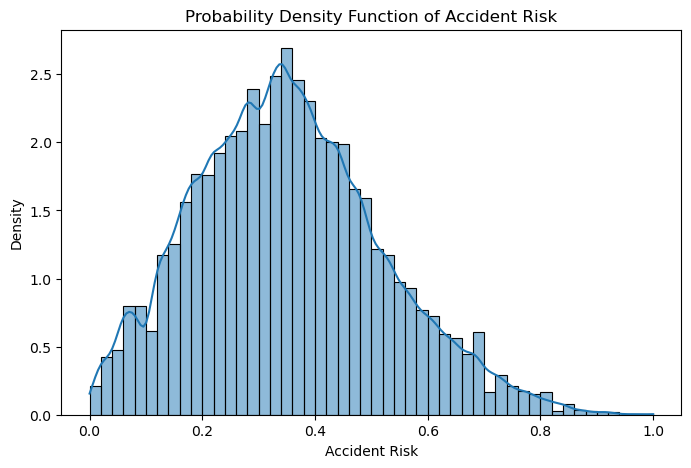

In [12]:
plt.figure(figsize=(8,5))

sn.histplot(road_data['accident_risk'],
            bins=50,
            kde=True,
            stat='density')

plt.title("Probability Density Function of Accident Risk")
plt.xlabel("Accident Risk")
plt.ylabel("Density")

plt.savefig('accident_risk.pdf',
            format='pdf')

plt.show()

In [13]:
road_data['accident_risk'].skew()

np.float64(0.37841797634228086)

-The target is already bounded between 0 and 1 and has only a mild right skew (about 0.38).

-Unlike trip duration in the taxi data, no log transformation is needed.

## UNIVARIATE VISUALIZATION

##### Road Type

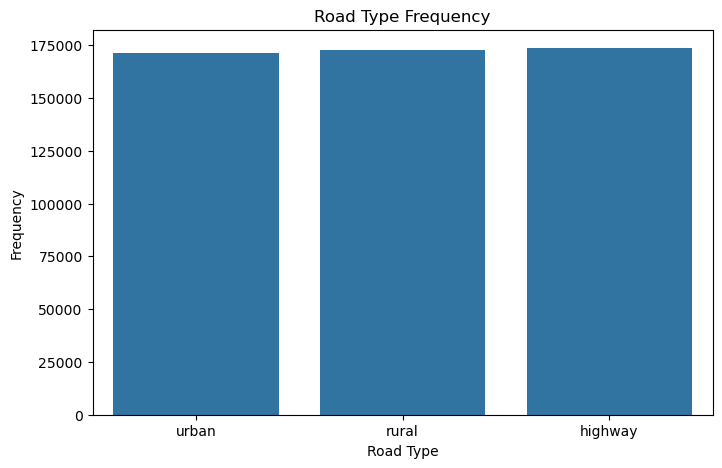

In [14]:
plt.figure(figsize=(8,5))

sn.countplot(x='road_type', data=road_data)

plt.title("Road Type Frequency")
plt.xlabel("Road Type")
plt.ylabel("Frequency")

plt.show()

-Highway, rural and urban roads each make up about one third of the records.

##### Lighting and Weather

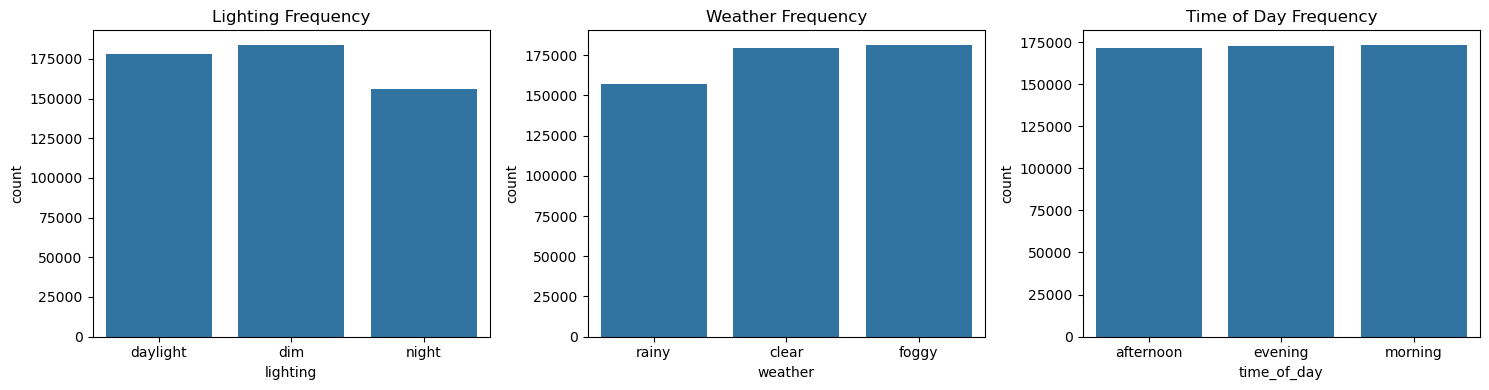

In [15]:
fig, axes = plt.subplots(1,3, figsize=(15,4))

sn.countplot(x='lighting', data=road_data, ax=axes[0])
axes[0].set_title('Lighting Frequency')

sn.countplot(x='weather', data=road_data, ax=axes[1])
axes[1].set_title('Weather Frequency')

sn.countplot(x='time_of_day', data=road_data, ax=axes[2])
axes[2].set_title('Time of Day Frequency')

plt.tight_layout()
plt.show()

-Lighting, weather and time of day are all fairly balanced across their three categories.

-Night is the least common lighting condition (about 30% of records).

##### Number of Lanes and Speed Limit

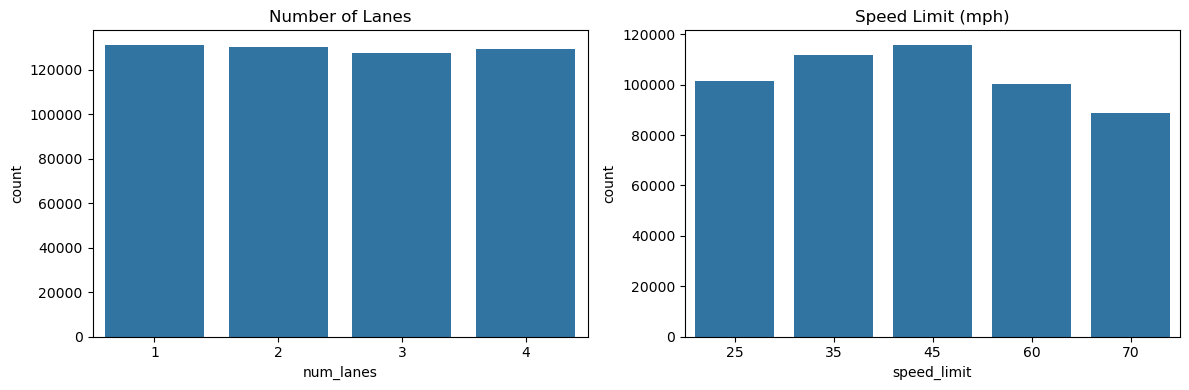

In [16]:
fig, axes = plt.subplots(1,2, figsize=(12,4))

sn.countplot(x='num_lanes', data=road_data, ax=axes[0])
axes[0].set_title('Number of Lanes')

sn.countplot(x='speed_limit', data=road_data, ax=axes[1])
axes[1].set_title('Speed Limit (mph)')

plt.tight_layout()
plt.show()

-Lanes 1 to 4 each account for about 25% of the roads.

-Speed limits come in five values: 25, 35, 45, 60 and 70 mph. 45 mph is the most common (about 22%) and 70 mph the least (about 17%).

##### Curvature

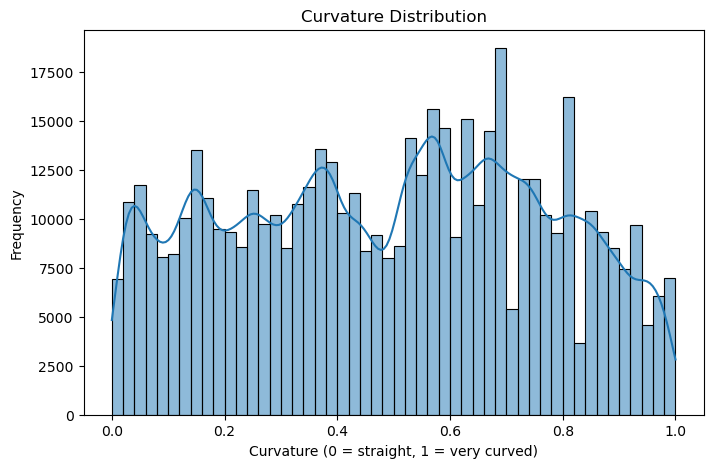

In [17]:
plt.figure(figsize=(8,5))

sn.histplot(road_data['curvature'], bins=50, kde=True)

plt.title("Curvature Distribution")
plt.xlabel("Curvature (0 = straight, 1 = very curved)")
plt.ylabel("Frequency")

plt.show()

-Curvature runs from 0 to 1 with a mean of about 0.49, so roads range from straight to very curved.

##### Number of Reported Accidents

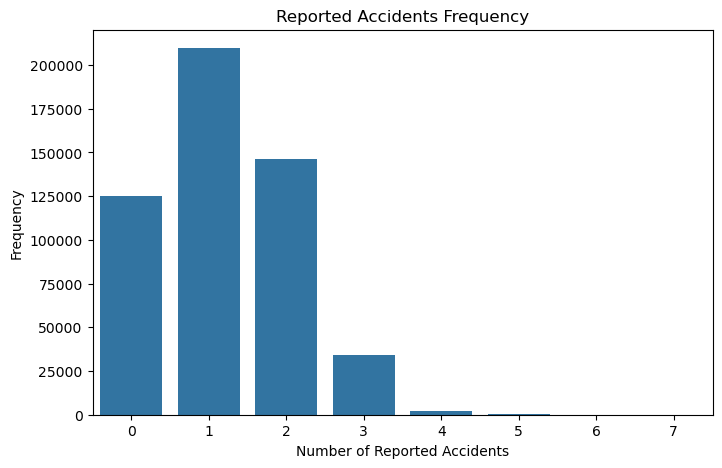

In [18]:
plt.figure(figsize=(8,5))

sn.countplot(x='num_reported_accidents', data=road_data)

plt.title("Reported Accidents Frequency")
plt.xlabel("Number of Reported Accidents")
plt.ylabel("Frequency")

plt.show()

-Roads with 0, 1 or 2 reported accidents make up about 93% of the data.

-Counts of 4 and above are very rare (under 1%), so averages for those groups are noisy.

##### True/False Flags

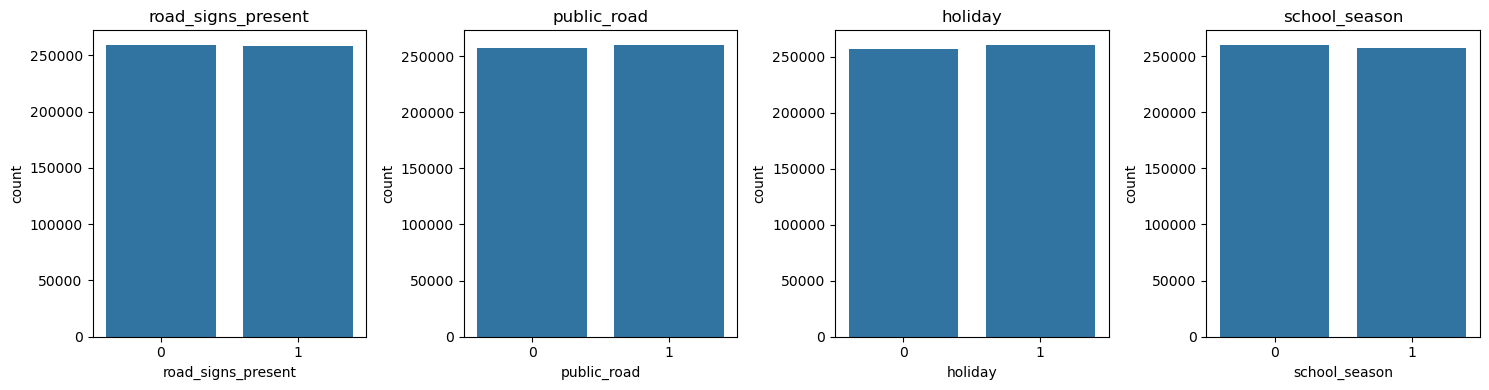

In [19]:
fig, axes = plt.subplots(1,4, figsize=(15,4))

for ax, c in zip(axes, flag_cols):
    sn.countplot(x=c, data=road_data, ax=ax)
    ax.set_title(c)

plt.tight_layout()
plt.show()

-Each flag is split almost exactly 50/50 between 0 and 1.

## Bivariate Relationship with Target

#### Accident Risk vs Lighting and Weather

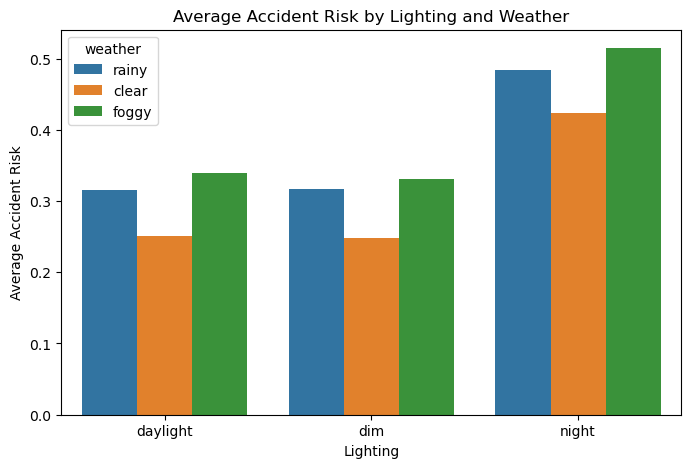

In [20]:
plt.figure(figsize=(8,5))

sn.barplot(data=road_data,
           x='lighting',
           y='accident_risk',
           hue='weather',
           errorbar=None)

plt.title('Average Accident Risk by Lighting and Weather')
plt.xlabel('Lighting')
plt.ylabel('Average Accident Risk')

plt.show()

-Night roads have clearly higher risk (about 0.47) than dim (about 0.30) or daylight (about 0.30) roads.

-Foggy and rainy weather raise risk in every lighting condition. Clear weather is the safest.

#### Accident Risk vs Speed Limit

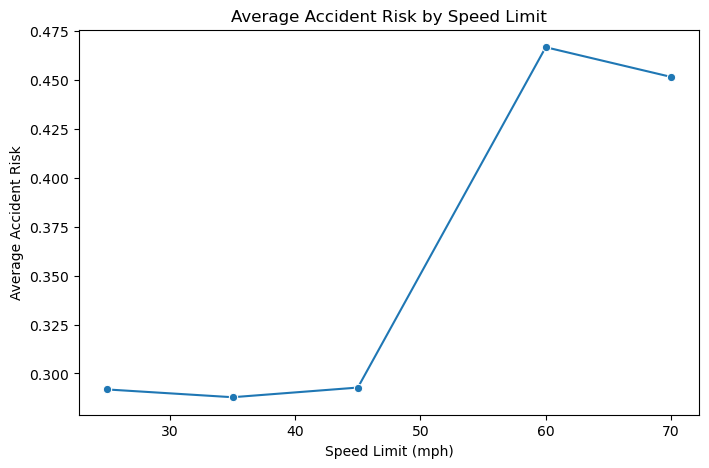

In [21]:
plt.figure(figsize=(8,5))

sn.lineplot(data=road_data,
            x='speed_limit',
            y='accident_risk',
            estimator='mean',
            errorbar=None,
            marker='o')

plt.title('Average Accident Risk by Speed Limit')
plt.xlabel('Speed Limit (mph)')
plt.ylabel('Average Accident Risk')

plt.show()

-Risk is flat (about 0.29) up to 45 mph, then jumps to about 0.45 to 0.47 at 60 and 70 mph.

#### Accident Risk vs Curvature

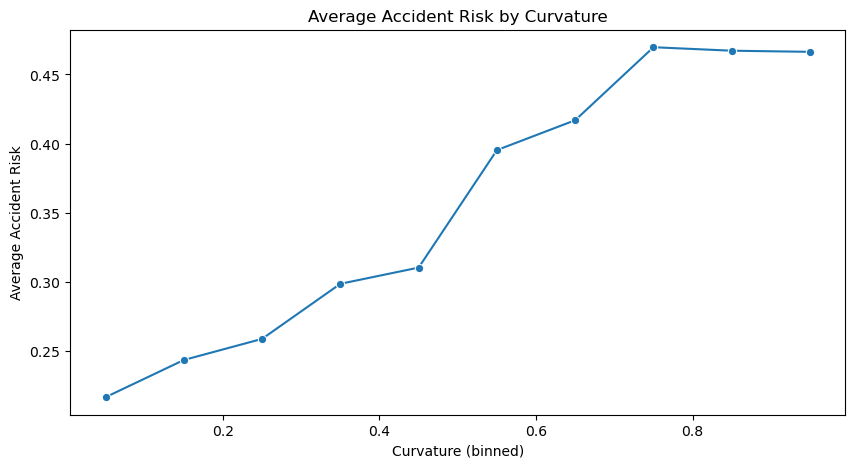

In [22]:
road_data['curvature_bin'] = pd.cut(road_data['curvature'], bins=10)

plt.figure(figsize=(10,5))

sn.lineplot(data=road_data.groupby('curvature_bin', observed=True)['accident_risk'].mean().reset_index().assign(curvature_bin=lambda d: d['curvature_bin'].apply(lambda i: round(i.mid,2))),
            x='curvature_bin',
            y='accident_risk',
            marker='o')

plt.title('Average Accident Risk by Curvature')
plt.xlabel('Curvature (binned)')
plt.ylabel('Average Accident Risk')

plt.show()

-Risk rises steadily as roads become more curved. Curvature has the strongest correlation with the target (about 0.54).

#### Accident Risk vs Number of Reported Accidents

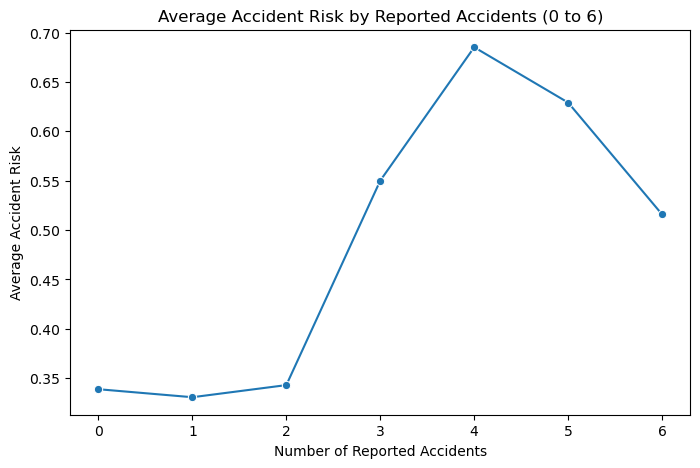

In [23]:
plt.figure(figsize=(8,5))

sn.lineplot(data=road_data[road_data['num_reported_accidents'] <= 6],
            x='num_reported_accidents',
            y='accident_risk',
            estimator='mean',
            errorbar=None,
            marker='o')

plt.title('Average Accident Risk by Reported Accidents (0 to 6)')
plt.xlabel('Number of Reported Accidents')
plt.ylabel('Average Accident Risk')

plt.show()

-Risk is about 0.33 to 0.34 for 0, 1 and 2 reported accidents, then jumps above 0.5 from 3 accidents.

-The relationship is not a straight line, so tree-based models should work better than linear regression.

#### Accident Risk Distribution by Lighting

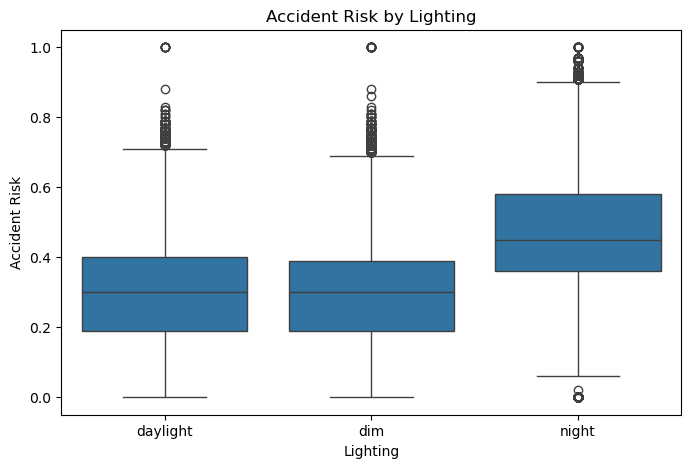

In [24]:
plt.figure(figsize=(8,5))

sn.boxplot(data=road_data,
           x='lighting',
           y='accident_risk')

plt.title('Accident Risk by Lighting')
plt.xlabel('Lighting')
plt.ylabel('Accident Risk')

plt.show()

-The whole night distribution sits higher than dim and daylight, not only the average.

#### Speed Limit and Curvature Together

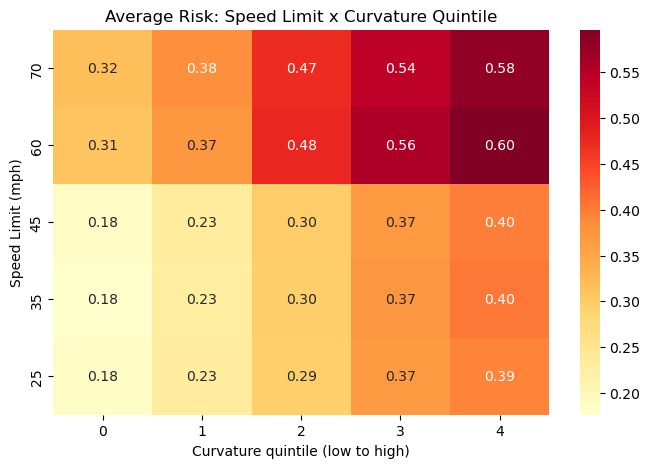

In [25]:
road_data['curv_quintile'] = pd.cut(road_data['curvature'], 5, labels=False)
pivot = road_data.pivot_table(index='speed_limit', columns='curv_quintile', values='accident_risk', aggfunc='mean')

plt.figure(figsize=(8,5))

sn.heatmap(pivot.sort_index(ascending=False), annot=True, fmt='.2f', cmap='YlOrRd')

plt.title('Average Risk: Speed Limit x Curvature Quintile')
plt.xlabel('Curvature quintile (low to high)')
plt.ylabel('Speed Limit (mph)')

plt.show()

-Risk is highest where high speed limits meet very curved roads, so the two variables interact. A product feature `curvature x speed_limit` is added later.

## Correlation Heatmap

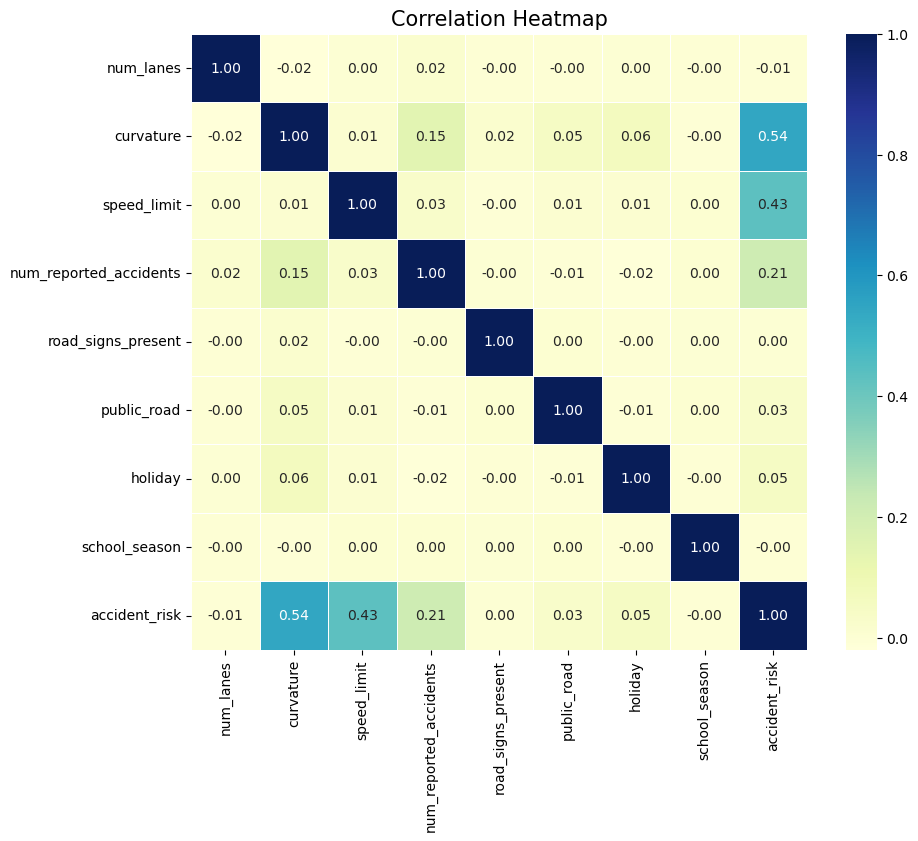

In [26]:
corr = road_data[['num_lanes','curvature','speed_limit','num_reported_accidents',
                  'road_signs_present','public_road','holiday','school_season','accident_risk']].corr()

plt.figure(figsize=(10,8))

sn.heatmap(corr,
           annot=True,
           fmt='.2f',
           cmap='YlGnBu',
           linewidths=0.5,
           square=True,
           cbar=True)

plt.title('Correlation Heatmap', fontsize=15)

plt.show()

-Curvature (0.54), speed limit (0.43) and reported accidents (0.21) have the strongest correlation with accident risk.

-Number of lanes, road signs and school season are close to 0, so they add little on their own.

-Correlation only captures straight-line relationships, so lighting, weather and the accident jump above 3 are not fully shown here.

## Feature Engineering

In [27]:
road_data = road_data.drop(columns=['curvature_bin','curv_quintile'])

cat_cols = ['road_type','lighting','weather','time_of_day']
categories = {c: sorted(road_data[c].unique()) for c in cat_cols}

def prepare(df):
    d = df.copy()
    for c in flag_cols:
        d[c] = d[c].astype(int)
    for c in cat_cols:
        d[c] = pd.Categorical(d[c], categories=categories[c])
    d['curv_x_speed'] = d['curvature'] * d['speed_limit']
    d['night'] = (d['lighting'] == 'night').astype(int)
    d['acc_ge3'] = (d['num_reported_accidents'] >= 3).astype(int)
    return d

X = prepare(road_data.drop(columns=['id','accident_risk']))
y = road_data['accident_risk']
X.dtypes

road_type                 category
num_lanes                    int64
curvature                  float64
speed_limit                  int64
lighting                  category
weather                   category
road_signs_present           int64
public_road                  int64
time_of_day               category
holiday                      int64
school_season                int64
num_reported_accidents       int64
curv_x_speed               float64
night                        int64
acc_ge3                      int64
dtype: object

## Train / Validation Split

In [28]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_val.shape

((414203, 15), (103551, 15))

## Model Building

##### Baseline: predict the mean

In [29]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

results = {}
base_pred = np.full(len(y_val), y_train.mean())
results['Mean baseline'] = [rmse(y_val, base_pred), mean_absolute_error(y_val, base_pred), 0.0]
results

{'Mean baseline': [0.16617308107558817, 0.13269335667745616, 0.0]}

##### Linear model (Ridge)

In [30]:
X_oh = pd.get_dummies(X, columns=cat_cols, dtype=int)
ridge = Ridge(alpha=1.0).fit(X_oh.loc[X_train.index], y_train)
p = ridge.predict(X_oh.loc[X_val.index])
results['Ridge'] = [rmse(y_val, p), mean_absolute_error(y_val, p), r2_score(y_val, p)]
results['Ridge']

[0.07075372040873999, 0.05606294323136774, 0.8187000676687072]

##### Random Forest (150,000-row sample to keep it fast)

In [31]:
sample = X_oh.loc[X_train.index].sample(150000, random_state=1)
rf = RandomForestRegressor(n_estimators=120, min_samples_leaf=5, max_features=0.6,
                           n_jobs=-1, random_state=0).fit(sample, y_train.loc[sample.index])
p = rf.predict(X_oh.loc[X_val.index])
results['Random Forest'] = [rmse(y_val, p), mean_absolute_error(y_val, p), r2_score(y_val, p)]
results['Random Forest']

[0.05732439806564828, 0.04447267258164675, 0.8809914713004209]

##### Gradient Boosting

In [32]:
gb = HistGradientBoostingRegressor(learning_rate=0.06, max_iter=1500, max_leaf_nodes=31,
                                   min_samples_leaf=40, l2_regularization=1.0,
                                   early_stopping=True, validation_fraction=0.1, n_iter_no_change=40,
                                   categorical_features='from_dtype', random_state=0).fit(X_train, y_train)
gb_pred = np.clip(gb.predict(X_val), 0, 1)
results['Gradient Boosting'] = [rmse(y_val, gb_pred), mean_absolute_error(y_val, gb_pred), r2_score(y_val, gb_pred)]
results['Gradient Boosting']

[0.05630480772888956, 0.0437025046127486, 0.8851872711376869]

## Model Comparison

In [33]:
comparison = pd.DataFrame(results, index=['RMSE','MAE','R2']).T.round(4)
comparison

,RMSE,MAE,R2
Mean baseline,0.1662,0.1327,0.0000
Ridge,0.0708,0.0561,0.8187
Random Forest,0.0573,0.0445,0.8810
Gradient Boosting,0.0563,0.0437,0.8852


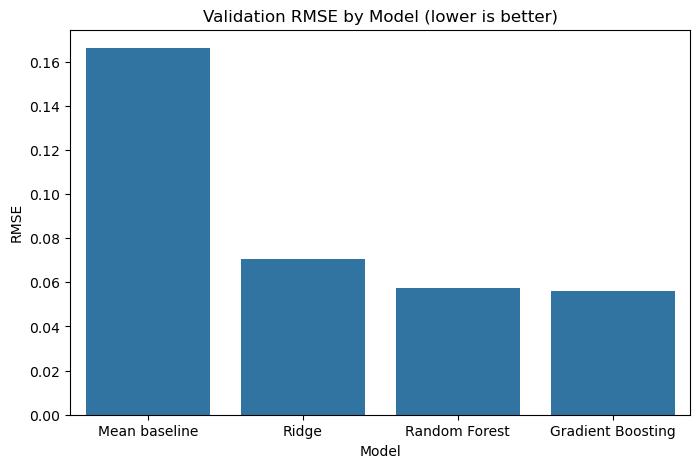

In [34]:
plt.figure(figsize=(8,5))

sn.barplot(x=comparison.index, y=comparison['RMSE'])

plt.title('Validation RMSE by Model (lower is better)')
plt.xlabel('Model')
plt.ylabel('RMSE')

plt.show()

-Every model beats the mean baseline (RMSE about 0.166).

-Gradient boosting is best (RMSE about 0.056, R2 about 0.885), ahead of the random forest and well ahead of the linear model.

-The gap to Ridge confirms that the relationships are non-linear and involve interactions.

## Predicted vs Actual

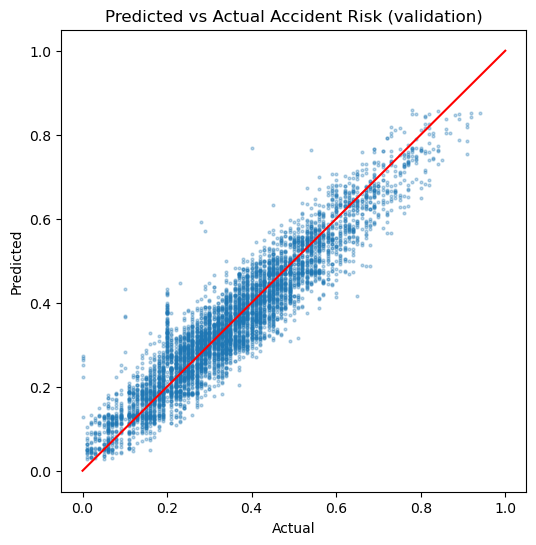

In [35]:
idx = np.random.RandomState(0).choice(len(y_val), 6000, replace=False)

plt.figure(figsize=(6,6))

plt.scatter(y_val.values[idx], gb_pred[idx], s=4, alpha=0.3)
plt.plot([0,1],[0,1], color='red')

plt.title('Predicted vs Actual Accident Risk (validation)')
plt.xlabel('Actual')
plt.ylabel('Predicted')

plt.show()

-Points follow the red diagonal closely, so predictions are well calibrated across the range.

## Feature Importance

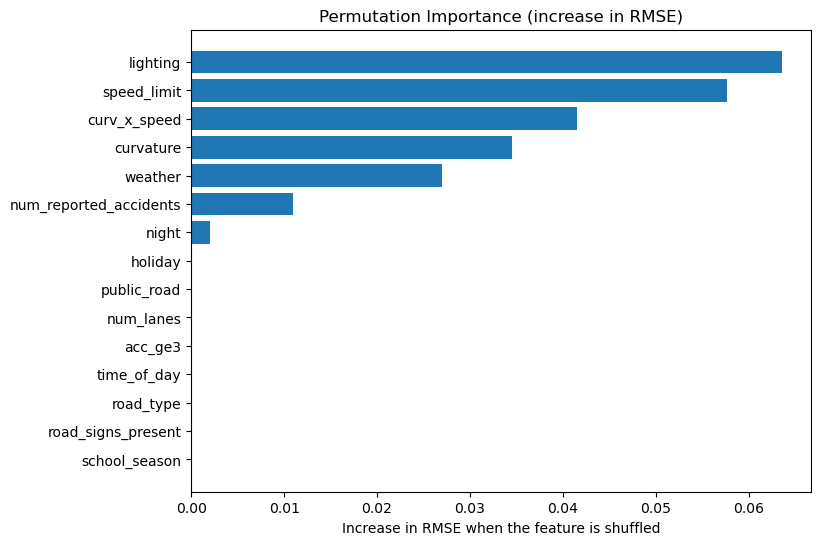

In [36]:
val_sample = X_val.sample(30000, random_state=0)
pi = permutation_importance(gb, val_sample, y_val.loc[val_sample.index], n_repeats=3,
                            random_state=0, scoring='neg_root_mean_squared_error', n_jobs=1)
importance = pd.Series(pi.importances_mean, index=val_sample.columns).sort_values()

plt.figure(figsize=(8,6))

plt.barh(importance.index, importance.values)

plt.title('Permutation Importance (increase in RMSE)')
plt.xlabel('Increase in RMSE when the feature is shuffled')

plt.show()

-Lighting, speed limit, curvature (and the curvature x speed feature) and weather matter most.

-Road type, lanes, road signs, school season and time of day add almost nothing.

## Final Model, Predictions and Saved Model

In [37]:
final = HistGradientBoostingRegressor(learning_rate=0.06, max_iter=int(gb.n_iter_ * 1.1), max_leaf_nodes=31,
                                      min_samples_leaf=40, l2_regularization=1.0,
                                      categorical_features='from_dtype', random_state=0).fit(X, y)

X_test = prepare(test_data.drop(columns='id'))[X.columns]
submission = pd.DataFrame({'id': test_data['id'], 'accident_risk': np.clip(final.predict(X_test), 0, 1)})
submission.to_csv('my_submission.csv', index=False)
submission.head()

,id,accident_risk
0,517754,0.298153
1,517755,0.123865
2,517756,0.179020
3,517757,0.316411
4,517758,0.398107


In [38]:
# model file used by the Flask web app
joblib.dump({'model': final, 'cats': categories, 'cols': list(X.columns)}, 'model.joblib', compress=3)

['model.joblib']

## Quick prediction for one road

In [39]:
example = pd.DataFrame([{'road_type':'highway','num_lanes':2,'curvature':0.9,'speed_limit':70,'lighting':'night',
                         'weather':'foggy','road_signs_present':0,'public_road':1,'time_of_day':'evening',
                         'holiday':0,'school_season':0,'num_reported_accidents':3}])
float(np.clip(final.predict(prepare(example)[X.columns])[0], 0, 1))

0.820741167718308